<table style="width: 100%; border: none; background: #f8f9fa; padding: 20px; border-radius: 10px;">
    <tr>
        <td style="width: 22%; border: none; vertical-align: middle; text-align: center;">
            <img src="https://www.inf.ucv.cl/wp-content/uploads/2020/05/logo_escuela.jpg" width="170">
        </td>
        <td style="width: 56%; border: none; vertical-align: middle; text-align: center; padding: 0 20px;">
            <h1 style="font-size: 28px; color: #1a3b5c; margin-bottom: 16px; border-bottom: 2px solid #1a3b5c; padding-bottom: 8px;">Tarea 2: Clasificacion, Costos Asimetricos y Arboles</h1>
            <p style="font-size: 16px; margin: 8px 0;"><strong>Pontificia Universidad Catolica de Valparaiso</strong><br>
            <strong>Escuela de Ingenieria Informatica</strong></p>
            <p style="font-size: 14px; color: #333; margin: 12px 0;"><strong>OII432 Machine Learning</strong><br>
            <strong>Semestre: 2-2026</strong><br>
            <strong>Profesor: Carlos Valle</strong></p>
        </td>
        <td style="width: 22%; border: none; vertical-align: middle; text-align: center;">
            <img src="https://upload.wikimedia.org/wikipedia/commons/c/cb/PUCV_Escudo2016.svg" width="110">
        </td>
    </tr>
</table>

# Pregunta 2: desafío Kaggle
Integrantes:
- Nelson Fuentes
- Eduardo Pérez
- Eduardo Sandoval
- Ricardo Pastén

Se predice si una licitación quedará desierta con información disponible al publicarla. La pauta adjunta confirma que la métrica es F1 para la clase desierta.


El trabajo sigue estas seis partes. Los costos son pesos para comparar errores; F1 sigue siendo la métrica de Kaggle.

| Parte | Pregunta 1 | Adaptación para pregunta 2 |
|---|---|---|
| 1. Datos y protocolo | Carga, faltantes, partición y costos | Carga, faltantes, desbalance, partición por fecha y costo de cada error |
| 2. Regresión logística | Entrenamiento, regularización y balanceo | Regresión logística con datos de la licitación, texto y publicaciones anteriores |
| 3. Comparación de modelos | LDA, QDA y Naive Bayes | Comparación de regresión logística, árbol y Random Forest |
| 4. Evaluación y umbral | ROC, PR y umbral por costos | Curvas ROC y PR, umbral que maximiza F1 y revisión del costo ponderado |
| 5. Árboles y ensambles | Árboles, poda, Bagging y Random Forest | Análisis del árbol y de Random Forest, sin añadir modelos |
| 6. Decisión final | Modelo elegido, resultados y discusión | Modelo elegido, evaluación temporal, errores y archivo para Kaggle |


## Librerías


In [85]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, brier_score_loss, confusion_matrix,
    f1_score, precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve
)
from sklearn.model_selection import ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

SEED = 42
TARGET = "y_desierta"
plt.rcParams["figure.figsize"] = (12, 5)
sns.set_palette("deep")
print(f"NumPy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")

NumPy 1.26.2 | pandas 2.3.3 | scikit-learn 1.9.1


# 1. Datos y protocolo

Se predice `y_desierta`: **1** significa que la licitación quedó desierta y **0**, que no quedó desierta. Primero se revisan los archivos, los datos faltantes y la distribución de ambas clases. Después se separan los datos por fecha y se fija cuánto pesa cada tipo de error.


### Carga de datos

In [86]:
train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")
assert list(pd.read_csv("sample_submission.csv", nrows=0).columns) == ["id", TARGET]
# Solo se leen los identificadores de la plantilla; sus etiquetas de ejemplo se ignoran.
sample_submission_df = pd.read_csv("sample_submission.csv", usecols=["id"])

### Inspección e integridad

In [87]:
for nombre, df in {"train": train_df, "test": test_df}.items():
    print(nombre, df.shape)
    display(df.head(3))

train (152553, 24)


,id,pub_fecha,pub_titulo,pub_descripcion,pub_monto_estimado,pub_moneda,pub_metodo,pub_modalidad,pub_n_items,pub_cantidad_total,...,pub_cierre,pub_dias_postulacion,pub_tiene_consultas,pub_dias_consultas,comprador,comprador_id,comprador_rut,region,direccion,y_desierta
0,248328745624,2024-03-25T15:32:20Z,LP04-2024 AV. UNO SUR AYSEN,"CONSTRUCCIÓN CALZADA H.C.V. AVENIDA UNO SUR, P...",NaN,NaN,open,Licitación Pública MOP (O1),1,1.0,...,2024-04-12T10:00:00Z,17.769,False,11.0,SERVICIO DE VIVIENDA Y URBANIZACION XI REGION ...,CL-MP-1653,618230007,Región Aysén del General Carlos Ibáñez del Campo,RAMON FREIRE Nº 5,0
1,760555527084,2024-03-21T14:29:28Z,LICITACION PUBLICA PARA OBRAS DE INFRAESTRUCTU...,licitar las obras de infraestructura de mejora...,NaN,NaN,open,Licitación Pública entre a 2000 y 5000 UTM (LQ),1,1.0,...,2024-04-15T20:00:00Z,25.230,False,21.0,CORPORACION MUNICIPAL DE EDUCACION Y SALUD DE ...,CL-MP-1274286,709255002,Región Metropolitana de Santiago,O'HIGGINS 840,1
2,224829110991,2024-01-26T12:37:41Z,ADQUISICION DE INSUMOS DE ENFERMERÍA PARA DSM,ADQUISICION DE INSUMOS DE ENFERMERÍA PARA USUA...,3500000.0,CLP,open,Licitación Pública Menor a 100 UTM (L1),55,12150.0,...,2024-02-01T13:24:00Z,6.032,False,3.0,I MUNICIPALIDAD DE CHANCO | I MUNICIPALIDAD DE...,CL-MP-4391,69120300K,Región del Maule,Ignacio Carrera Pinto Nº 31,0


test (21829, 23)


,id,pub_fecha,pub_titulo,pub_descripcion,pub_monto_estimado,pub_moneda,pub_metodo,pub_modalidad,pub_n_items,pub_cantidad_total,...,pub_inicio,pub_cierre,pub_dias_postulacion,pub_tiene_consultas,pub_dias_consultas,comprador,comprador_id,comprador_rut,region,direccion
0,47254358932,2025-03-12T15:46:53Z,SC 36914 (CM) ADQUISICIÓN DE MOBILIARIO PARA C...,ADQUISICIÓN DE MOBILIARIO PARA CLÍNICA JURÍDIC...,4999999.0,CLP,open,Licitación Pública Menor a 100 UTM (L1),3,24.0,...,2025-03-12T15:46:47Z,2025-03-20T15:30:00Z,7.988,False,2.0,UNIVERSIDAD DE PLAYA ANCHA DE CIENCIAS DE LA E...,CL-MP-5385,707547006,Región Metropolitana de Santiago,Av. A Bello 2687
1,295671198916,2025-01-06T17:34:25Z,COMPRA DE MEDICAMENTOS PARA DEPTO SALUD MAULE,COMPRA DE MEDICAMENTOS PARA DEPTO SALUD MAULE,20000000.0,CLP,open,Licitación Pública Entre 100 y 1000 UTM (LE),45,123593.0,...,2025-01-06T17:34:19Z,2025-01-16T19:53:00Z,10.096,False,3.0,I MUNICIPALIDAD DE MAULE | I MUNICIPALIDAD DE ...,CL-MP-5605,691109003,Región del Maule,Balmaceda N° 350
2,214756376398,2025-02-26T12:48:51Z,ADQUISICIÓN DE BOLSAS CORPORATIVAS REUTILIZABL...,ADQUISICIÓN DE BOLSAS CORPORATIVAS REUTILIZABL...,NaN,NaN,open,Licitación Pública Entre 100 y 1000 UTM (LE),1,19000.0,...,2025-02-26T12:48:41Z,2025-03-03T15:00:00Z,5.091,False,2.0,I MUNICIPALIDAD DE QUILICURA | DEPARTAMENTO CO...,CL-MP-3475,690713004,Región Metropolitana de Santiago,NaN


In [88]:
train_df.info()
test_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 152553 entries, 0 to 152552
Data columns (total 24 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    152553 non-null  int64  
 1   pub_fecha             152553 non-null  object 
 2   pub_titulo            152544 non-null  object 
 3   pub_descripcion       152544 non-null  object 
 4   pub_monto_estimado    85287 non-null   float64
 5   pub_moneda            85251 non-null   object 
 6   pub_metodo            152485 non-null  object 
 7   pub_modalidad         152553 non-null  object 
 8   pub_n_items           152553 non-null  int64  
 9   pub_cantidad_total    152553 non-null  float64
 10  pub_categoria         152528 non-null  object 
 11  pub_categoria_id      152528 non-null  float64
 12  pub_n_categorias      152553 non-null  int64  
 13  pub_inicio            152553 non-null  object 
 14  pub_cierre            152526 non-null  object 
 15  

In [89]:
assert TARGET in train_df and TARGET not in test_df
assert train_df[TARGET].notna().all()
assert set(train_df[TARGET].unique()) == {0, 1}
assert set(train_df.columns) - {TARGET} == set(test_df.columns)
assert len(train_df) == 152553 and len(test_df) == 21829
for df in (train_df, test_df, sample_submission_df):
    assert df["id"].notna().all() and df["id"].is_unique
assert set(train_df["id"]).isdisjoint(test_df["id"])
assert sample_submission_df["id"].equals(test_df["id"])
assert TARGET not in sample_submission_df

### Distribución de la clase objetivo

In [90]:
frecuencias = train_df[TARGET].value_counts().sort_index()
pd.DataFrame({"registros": frecuencias, "porcentaje": 100 * frecuencias / len(train_df)})

,registros,porcentaje
y_desierta,,
0,122006,79.976139
1,30547,20.023861


Cerca del 20% de las licitaciones de 2024 quedaron desiertas y el 80% no. Por eso, predecir siempre «no desierta» acertaría muchas veces, pero no detectaría ningún caso desierto. La distribución de todo 2024 se muestra como descripción. Los pesos de los errores se calculan más abajo usando solo el entrenamiento anterior a agosto.


### Valores nulos

In [91]:
nulos = train_df.isna().sum()
pd.DataFrame({"nulos": nulos, "porcentaje": 100 * nulos / len(train_df)})

,nulos,porcentaje
id,0,0.000000
pub_fecha,0,0.000000
pub_titulo,9,0.005900
pub_descripcion,9,0.005900
pub_monto_estimado,67266,44.093528
pub_moneda,67302,44.117127
pub_metodo,68,0.044575
pub_modalidad,0,0.000000
pub_n_items,0,0.000000
pub_cantidad_total,0,0.000000


`pub_monto_estimado` y `pub_moneda` tienen cerca del 44% de valores nulos.

### Ausencia de monto y moneda

In [92]:
pd.crosstab(
    train_df["pub_monto_estimado"].isna(),
    train_df["pub_moneda"].isna(),
    rownames=["Monto nulo"],
    colnames=["Moneda nula"]
)

Moneda nula,False,True
Monto nulo,,
False,85251,36
True,0,67266


Los 67.266 registros sin monto tampoco tienen moneda; otros 36 tienen monto, pero no moneda. Se conservan ambos indicadores de ausencia y la moneda como categoría. Se excluye el monto bruto porque no hay conversión temporal verificable entre monedas.

### Ausencia de monto por categoría

In [93]:
resumen_categoria_montos = train_df.groupby("pub_categoria", dropna=False)["pub_monto_estimado"].agg(
    total="size",
    porcentaje_nulos=lambda valores: 100 * valores.isna().mean()
)
resumen_categoria_montos.query("total >= 30").sort_values(
    ["porcentaje_nulos", "total"], ascending=[False, False]
).head(20)

,total,porcentaje_nulos
pub_categoria,,
Obras MINVU / Obras MINVU / Grupo 2 / 3°,190,100.000000
Obras MINVU / Obras MINVU / Grupo 2 / 2°,105,100.000000
Obras MINVU / Obras MINVU / Grupo 2 / 1°,85,100.000000
Obras / Obras Mayores / Obra Civil / 2da,77,100.000000
Consultoria / Consultoria / Inspecciones / 1a S,71,100.000000
Obras /Obras Menores/Obra Menor / A,48,100.000000
Consultoria / Consultoria / Ingeniería Civil / 1a S,47,100.000000
Consultoria / Consultoria / Inspecciones / 2da,41,100.000000
Obras / Obras Mayores / Obra Civil / 3,39,100.000000


Algunas categorías tienen todos sus montos ausentes. Se muestran las de al menos 30 registros para reducir el peso de grupos pequeños. Esta exploración no usa el objetivo.

### Fechas y particiones temporales

In [94]:
datos = train_df.copy()
datos["pub_fecha"] = pd.to_datetime(datos["pub_fecha"], errors="raise", utc=True)
fechas_test = pd.to_datetime(test_df["pub_fecha"], errors="raise", utc=True)
assert datos["pub_fecha"].notna().all() and fechas_test.notna().all()
assert datos["pub_fecha"].between("2024-01-01", "2025-01-01", inclusive="left").all()
assert fechas_test.between("2025-01-01", "2025-04-01", inclusive="left").all()

Se separan las publicaciones por fecha, sin mezclarlas al azar:

| Bloque | Publicaciones, UTC | Uso |
|---|---|---|
| A: entrenamiento inicial | Antes del 1 de agosto de 2024 | Entrenar y calcular los pesos de los errores |
| B: validación de modelos | Agosto y septiembre de 2024 | Comparar modelos y elegir sus parámetros |
| C: validación del umbral | 1 de octubre a 14 de noviembre | Elegir el umbral que maximiza F1 |
| D: evaluación final | 15 de noviembre a 31 de diciembre | Evaluar las decisiones ya fijadas |
| E: datos de Kaggle | Primer trimestre de 2025 | Predecir; no se conocen sus etiquetas |

El modelo se elige con la validación de agosto y septiembre. El umbral se elige con la validación de octubre y noviembre. La evaluación final no se usa para cambiar esas decisiones. Los cortes respetan las fechas de publicación, pero no conocemos cuándo se hizo disponible el resultado de cada licitación; esa limitación debe tenerse presente al interpretar la evaluación.


In [95]:
CORTE_HPARAM = pd.Timestamp("2024-08-01", tz="UTC")
CORTE_UMBRAL = pd.Timestamp("2024-10-01", tz="UTC")
CORTE_EVALUACION = pd.Timestamp("2024-11-15", tz="UTC")
FIN_2024 = pd.Timestamp("2025-01-01", tz="UTC")

fecha = datos["pub_fecha"]
train_modelos = datos.loc[fecha < CORTE_HPARAM].copy()
val_hparam = datos.loc[fecha.between(CORTE_HPARAM, CORTE_UMBRAL, inclusive="left")].copy()
val_umbral = datos.loc[fecha.between(CORTE_UMBRAL, CORTE_EVALUACION, inclusive="left")].copy()
test_temporal = datos.loc[fecha >= CORTE_EVALUACION].copy()
train_hparam = pd.concat([train_modelos, val_hparam])
train_umbral = pd.concat([train_hparam, val_umbral])

bloques = {"A": train_modelos, "B": val_hparam, "C": val_umbral, "D": test_temporal}
assert all(len(df) > 0 for df in bloques.values())
ids_bloques = pd.concat([df["id"] for df in bloques.values()])
assert ids_bloques.is_unique and set(ids_bloques) == set(train_df["id"])
for anterior, siguiente in zip(list(bloques.values()), list(bloques.values())[1:]):
    assert anterior["pub_fecha"].max() < siguiente["pub_fecha"].min()
pd.DataFrame({
    nombre: {"registros": len(df), "desde": df["pub_fecha"].min(), "hasta": df["pub_fecha"].max()}
    for nombre, df in bloques.items()
}).T

,registros,desde,hasta
A,90904,2024-01-04 17:06:15+00:00,2024-07-31 23:27:03+00:00
B,25762,2024-08-01 07:36:56+00:00,2024-09-30 23:25:01+00:00
C,21308,2024-10-01 08:05:24+00:00,2024-11-14 22:17:01+00:00
D,14579,2024-11-15 09:42:08+00:00,2024-12-31 22:29:20+00:00


## Peso de las falsas alertas y de los casos no detectados

Una **falsa alerta (falso positivo, FP)** ocurre cuando se predice «desierta», pero la licitación no queda desierta. Un **caso no detectado (falso negativo, FN)** ocurre cuando queda desierta, pero se predice que no.

Para compensar el desbalance, fijamos estos pesos usando solo el entrenamiento anterior a agosto:

$$C_{FP}=1,\qquad C_{FN}=\frac{\text{licitaciones no desiertas en entrenamiento}}{\text{licitaciones desiertas en entrenamiento}}.$$

Hay 72.693 no desiertas y 18.211 desiertas. Así, una falsa alerta pesa **1** y una desierta no detectada pesa aproximadamente **3,99**. La suma que se reporta es:

$$\text{costo ponderado}=FP+3{,}9917\,FN.$$

El código usa la razón completa, sin redondearla. También muestra el costo dividido por el número de licitaciones para comparar bloques de distinto tamaño. Los pesos se mantienen fijos al evaluar agosto, octubre y el bloque final.

Este es un criterio elegido para compensar la frecuencia de las clases; no son montos en dinero ni una estimación del daño real. Usa la misma razón entre clases que los [pesos balanceados de scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.utils.class_weight.compute_class_weight.html), expresada en una escala donde la falsa alerta vale 1. Los pesos de entrenamiento ya existentes se siguen comparando sin cambios. El costo de evaluación se calcula una sola vez por error, a partir de las predicciones.


In [96]:
def definir_costos_desbalance(y_entrenamiento):
    conteos = pd.Series(y_entrenamiento).value_counts().reindex([0, 1], fill_value=0)
    if (conteos == 0).any():
        raise ValueError("Se necesitan ambas clases en entrenamiento para definir los costos.")
    return 1.0, float(conteos.loc[0] / conteos.loc[1])


# Se calculan una vez con A y se conservan para todas las evaluaciones posteriores.
C_FP, C_FN = definir_costos_desbalance(train_modelos[TARGET])


def costos_errores(y_real, y_pred):
    _, fp, fn, _ = confusion_matrix(y_real, y_pred, labels=[0, 1]).ravel()
    total = float(C_FP * fp + C_FN * fn)
    return {
        "falsos_positivos": int(fp), "falsos_negativos": int(fn),
        "costo_fp": float(C_FP * fp), "costo_fn": float(C_FN * fn),
        "costo_total": total, "costo_por_licitacion": total / len(y_real),
    }


def curva_costo_ponderado(y_real, probabilidades):
    # Se cuentan los errores en cada umbral sin volver a entrenar el modelo.
    y = np.asarray(y_real, dtype=int)
    p = np.asarray(probabilidades, dtype=float)
    orden = np.argsort(p, kind="stable")
    acumulado_desiertas = np.r_[0, np.cumsum(y[orden])]
    umbrales = np.unique(np.r_[0.0, p, np.nextafter(1.0, np.inf)])
    posiciones = np.searchsorted(p[orden], umbrales, side="left")
    fn = acumulado_desiertas[posiciones]
    tp = y.sum() - fn
    fp = len(y) - posiciones - tp
    return pd.DataFrame({
        "threshold": umbrales, "falsos_positivos": fp, "falsos_negativos": fn,
        "costo_por_licitacion": (C_FP * fp + C_FN * fn) / len(y),
    })


conteos_costos = train_modelos[TARGET].value_counts().sort_index()
display(pd.DataFrame({
    "Clase real": ["No desierta", "Desierta"],
    "Registros de entrenamiento": [conteos_costos.loc[0], conteos_costos.loc[1]],
    "Error al equivocarse": ["Falsa alerta (FP)", "Desierta no detectada (FN)"],
    "Costo relativo": [C_FP, C_FN],
}))

# Los nombres internos se conservan; las tablas se muestran en español.
ETIQUETAS_RESULTADOS = {
    "modelo": "Modelo", "threshold": "Umbral", "ap": "Average Precision",
    "f1": "F1", "precision": "Precisión", "recall": "Recall",
    "falsos_positivos": "Falsas alertas", "falsos_negativos": "Desiertas no detectadas",
    "costo_fp": "Costo de falsas alertas", "costo_fn": "Costo de casos no detectados",
    "costo_total": "Costo total", "costo_por_licitacion": "Costo por licitación",
    "roc_auc": "Área bajo ROC", "brier": "Error de probabilidades (Brier)",
    "tasa_observada": "Proporción real desierta", "tasa_predicha": "Proporción de alertas",
    "params": "Parámetros", "particion": "Bloque", "n": "Registros",
}


,Clase real,Registros de entrenamiento,Error al equivocarse,Costo relativo
0,No desierta,72693,Falsa alerta (FP),1.000000
1,Desierta,18211,Desierta no detectada (FN),3.991708


# 2. Regresión logística

La regresión logística entrega un puntaje entre 0 y 1 para cada licitación. Se prueban tres versiones con los mismos parámetros iniciales:

1. **Datos de la licitación:** plazos, cantidades, fecha, moneda, modalidad, región y datos faltantes.
2. **Datos y texto:** se añaden el título y la descripción. TF-IDF convierte las palabras y pares de palabras en columnas numéricas según su frecuencia.
3. **Datos, texto y publicaciones anteriores:** se añade cuántas licitaciones publicó antes el comprador, cuántas hubo antes en la categoría y cuántas coinciden en ambos. Son conteos de publicaciones, sin usar sus resultados.

Los conteos incluyen solo publicaciones con fecha estrictamente anterior. Dos publicaciones simultáneas no se cuentan entre sí. Así se evita usar el futuro o el propio resultado de la licitación para construir una variable. La [pauta de la tarea](Tarea2_OII432-2s-2026-v2.ipynb) indica que las columnas de origen estaban disponibles al publicar. `id` sirve solo para comprobar los registros y preparar la entrega.

También se prueba `proporcion_consultas = pub_dias_consultas / pub_dias_postulacion`. Si el denominador es cero o hay valores faltantes o infinitos, el cociente queda como faltante. La comparación posterior cambia solo esta columna y mantiene el mismo entrenamiento, validación, modelo y umbral.


In [97]:
COLUMNAS_ORIGEN = [
    "pub_fecha", "pub_titulo", "pub_descripcion", "pub_monto_estimado", "pub_moneda",
    "pub_metodo", "pub_modalidad", "pub_n_items", "pub_cantidad_total", "pub_n_categorias",
    "pub_dias_postulacion", "pub_dias_consultas", "pub_categoria", "pub_categoria_id",
    "comprador_id", "region"
]
ESTRUCTURA_NUMERICA = [
    "pub_n_items", "pub_cantidad_total", "pub_n_categorias",
    "pub_dias_postulacion", "pub_dias_consultas"
]
BASE_NUMERICAS = ESTRUCTURA_NUMERICA + [
    "monto_nulo", "moneda_nula", "titulo_largo", "descripcion_larga", "texto_palabras",
    "mes_publicacion", "dia_semana_publicacion", "cat_niveles", "proporcion_consultas"
]
CLAVES_HISTORICAS = {
    "hist_comprador_n": ["comprador_id"],
    "hist_categoria_n": ["pub_categoria_id"],
    "hist_comprador_categoria_n": ["comprador_id", "pub_categoria_id"]
}
HISTORICAS = list(CLAVES_HISTORICAS) + ["comprador_nuevo", "categoria_nueva"]
NUMERICAS = BASE_NUMERICAS + HISTORICAS
CATEGORICAS = ["pub_metodo", "pub_modalidad", "pub_moneda", "region", "categoria_principal"]
COLUMNAS_MODELO = NUMERICAS + CATEGORICAS + ["texto"]

def preparar_historial(df):
    historial = df[["pub_fecha", "comprador_id", "pub_categoria_id"]].copy()
    historial["pub_fecha"] = pd.to_datetime(historial["pub_fecha"], errors="raise", utc=True)
    assert historial["pub_fecha"].notna().all()
    for col in ("comprador_id", "pub_categoria_id"):
        historial[col] = historial[col].fillna("desconocido").astype(str)
    return historial

def crear_features_base(df):
    X = df[COLUMNAS_ORIGEN].copy()
    fecha = pd.to_datetime(X["pub_fecha"], errors="raise", utc=True)
    titulo = X["pub_titulo"].fillna("").astype(str)
    descripcion = X["pub_descripcion"].fillna("").astype(str)
    X["texto"] = titulo + " " + descripcion
    X["titulo_largo"] = titulo.str.len()
    X["descripcion_larga"] = descripcion.str.len()
    X["texto_palabras"] = X["texto"].str.split().str.len()
    X["monto_nulo"] = pd.to_numeric(X["pub_monto_estimado"], errors="raise").isna().astype(int)
    X["moneda_nula"] = X["pub_moneda"].isna().astype(int)
    X["mes_publicacion"] = fecha.dt.month
    X["dia_semana_publicacion"] = fecha.dt.dayofweek
    categoria = X["pub_categoria"].fillna("desconocido").astype(str)
    X["categoria_principal"] = categoria.str.split("/").str[0].str.strip()
    X["cat_niveles"] = categoria.str.count("/") + 1
    for col in ESTRUCTURA_NUMERICA:
        X[col] = pd.to_numeric(X[col], errors="raise")
    # Interacción por fila: no usa etiquetas ni estadísticas de otros registros.
    dias_consultas = X["pub_dias_consultas"]
    dias_postulacion = X["pub_dias_postulacion"]
    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        X["proporcion_consultas"] = (
            dias_consultas.where(np.isfinite(dias_consultas))
            / dias_postulacion.where(np.isfinite(dias_postulacion) & dias_postulacion.ne(0))
        ).replace([np.inf, -np.inf], np.nan)
    # Los NaN pasan al SimpleImputer de mediana ya existente, ajustado solo en train.
    for col in CATEGORICAS:
        X[col] = X[col].fillna("desconocido").astype(str)
    return X[BASE_NUMERICAS + CATEGORICAS + ["texto"]]

def agregar_conteo_historico(filas, referencia, claves):
    ref = referencia[claves].copy()
    ref["clave"] = list(map(tuple, ref.to_numpy()))
    ref["fecha_ns"] = referencia["pub_fecha"].astype("int64")
    fechas_por_clave = {
        clave: np.sort(grupo["fecha_ns"].to_numpy())
        for clave, grupo in ref.groupby("clave", sort=False)
    }
    vacio = np.array([], dtype=np.int64)
    conteos = [
        np.searchsorted(fechas_por_clave.get(clave, vacio), fecha, side="left")
        for clave, fecha in zip(
            map(tuple, filas[claves].to_numpy()), filas["pub_fecha"].astype("int64")
        )
    ]
    return pd.Series(np.log1p(conteos), index=filas.index)

def construir_features(df, referencia=None):
    X = crear_features_base(df)
    filas = preparar_historial(df)
    ref = filas if referencia is None else preparar_historial(referencia)
    for nombre, claves in CLAVES_HISTORICAS.items():
        X[nombre] = agregar_conteo_historico(filas, ref, claves)
    X["comprador_nuevo"] = X["hist_comprador_n"].eq(0).astype(int)
    X["categoria_nueva"] = X["hist_categoria_n"].eq(0).astype(int)
    return X[COLUMNAS_MODELO]

X_train_modelos = construir_features(train_modelos)
X_val_hparam = construir_features(val_hparam, referencia=train_modelos)
X_train_hparam = construir_features(train_hparam)
X_val_umbral = construir_features(val_umbral, referencia=train_hparam)
X_train_umbral = construir_features(train_umbral)
X_test_temporal = construir_features(test_temporal, referencia=train_umbral)

y_train_modelos = train_modelos[TARGET].astype(int)
y_val_hparam = val_hparam[TARGET].astype(int)
y_train_hparam = train_hparam[TARGET].astype(int)
y_val_umbral = val_umbral[TARGET].astype(int)
y_train_umbral = train_umbral[TARGET].astype(int)
y_test_temporal = test_temporal[TARGET].astype(int)
X_train_modelos.head()

,pub_n_items,pub_cantidad_total,pub_n_categorias,pub_dias_postulacion,pub_dias_consultas,monto_nulo,moneda_nula,titulo_largo,descripcion_larga,texto_palabras,...,hist_categoria_n,hist_comprador_categoria_n,comprador_nuevo,categoria_nueva,pub_metodo,pub_modalidad,pub_moneda,region,categoria_principal,texto
0,1,1.0,1,17.769,11.0,1,1,27,57,13,...,2.564949,0.000000,0,0,open,Licitación Pública MOP (O1),desconocido,Región Aysén del General Carlos Ibáñez del Campo,Obras MINVU,LP04-2024 AV. UNO SUR AYSEN CONSTRUCCIÓN CALZA...
1,1,1.0,1,25.230,21.0,1,1,61,146,32,...,7.433667,1.386294,0,0,open,Licitación Pública entre a 2000 y 5000 UTM (LQ),desconocido,Región Metropolitana de Santiago,Servicios de construcción y mantenimiento,LICITACION PUBLICA PARA OBRAS DE INFRAESTRUCTU...
2,55,12150.0,27,6.032,3.0,0,0,45,115,25,...,0.000000,0.000000,0,1,open,Licitación Pública Menor a 100 UTM (L1),CLP,Región del Maule,Equipamiento para laboratorios,ADQUISICION DE INSUMOS DE ENFERMERÍA PARA DSM ...
3,1,350.0,1,6.234,1.0,0,0,15,69,14,...,3.737670,2.079442,0,0,open,Licitación Pública Menor a 100 UTM (L1),CLP,Región Metropolitana de Santiago,Equipamiento y suministros médicos,GASA HIDROFILA SC 309 - SP 742 IDDOC 718225...
6,1,1.0,1,7.150,3.0,1,1,39,63,14,...,3.135494,0.000000,0,0,open,Licitación Pública Menor a 100 UTM (L1),desconocido,Región Metropolitana de Santiago,Artículos para plantas y animales,Adquisición de Insecticidas y Raticidas Adquis...


In [98]:
def ejecutar_pruebas_aceptacion():
    assert {"id", TARGET, "pub_monto_estimado"}.isdisjoint(COLUMNAS_MODELO)
    assert {"id", TARGET}.isdisjoint(COLUMNAS_ORIGEN)
    assert not any("tasa" in col for col in COLUMNAS_MODELO)
    assert list(X_train_modelos.columns) == COLUMNAS_MODELO

    # Casos límite de la única interacción nueva; no se altera ninguna otra columna.
    casos = pd.concat([train_modelos.iloc[[0]]] * 12, ignore_index=True)
    casos["pub_dias_consultas"] = [2, 0, 2, np.nan, 2, np.inf, -np.inf, 2, 2, 0, 2, 1e308]
    casos["pub_dias_postulacion"] = [4, 4, 0, 4, np.nan, 4, 4, np.inf, -np.inf, 0, -4, 1e-308]
    proporcion = crear_features_base(casos)["proporcion_consultas"]
    np.testing.assert_allclose(
        proporcion.to_numpy(),
        [0.5, 0, np.nan, np.nan, np.nan, np.nan, np.nan, np.nan, np.nan, np.nan, -0.5, np.nan],
        equal_nan=True,
    )
    assert not np.isinf(proporcion.to_numpy()).any()

    muestra = train_hparam.sort_values("pub_fecha").head(200).copy()
    esperado = construir_features(muestra)
    alterada = muestra.copy()
    alterada[TARGET] = np.random.default_rng(SEED).integers(0, 2, len(muestra))
    pd.testing.assert_frame_equal(esperado, construir_features(alterada))

    pasado = muestra.head(100)
    futuro = test_temporal.tail(100).copy()
    futuro["comprador_id"] = pasado.iloc[0]["comprador_id"]
    futuro["pub_categoria_id"] = pasado.iloc[0]["pub_categoria_id"]
    # Agregar o modificar registros futuros no cambia ninguna fila pasada.
    for bloque_futuro in (test_temporal.tail(100), futuro):
        ampliada = pd.concat([pasado, bloque_futuro])
        pd.testing.assert_frame_equal(
            construir_features(pasado), construir_features(ampliada).loc[pasado.index]
        )

    # Dos publicaciones simultáneas no cuentan entre sí; una anterior sí cuenta.
    empate = pd.concat([muestra.iloc[[0]]] * 3, ignore_index=True)
    empate.loc[0, "pub_fecha"] -= pd.Timedelta(seconds=1)
    conteos_empate = construir_features(empate)[list(CLAVES_HISTORICAS)]
    np.testing.assert_allclose(conteos_empate.to_numpy(), np.log1p([[0]*3, [1]*3, [1]*3]))
    pd.testing.assert_frame_equal(construir_features(empate.iloc[:2]), construir_features(empate).iloc[:2])

    # Auditoría directa de entrenamiento y de una ventana con referencia externa.
    for filas, referencia, features in (
        (train_hparam, train_hparam, X_train_hparam),
        (val_hparam, train_modelos, X_val_hparam)
    ):
        ref = preparar_historial(referencia)
        for idx, fila in preparar_historial(filas.sample(n=10, random_state=SEED)).iterrows():
            for nombre, claves in CLAVES_HISTORICAS.items():
                anteriores = ref["pub_fecha"].lt(fila["pub_fecha"])
                misma_clave = ref[claves].eq(fila[claves]).all(axis=1)
                assert np.isclose(features.loc[idx, nombre], np.log1p((anteriores & misma_clave).sum()))
    print("Lista blanca, invariancias, empates y conteos directos verificados.")

ejecutar_pruebas_aceptacion()

Lista blanca, invariancias, empates y conteos directos verificados.


## Preparación de los datos

Los números faltantes se completan con la mediana del entrenamiento y se ajusta su escala. Las categorías, como moneda y región, se convierten en columnas que indican su presencia. El texto se convierte en números con TF-IDF. Cada transformación se aprende solo con el entrenamiento correspondiente; en validación se usa lo ya aprendido.


In [99]:
def crear_preprocesamiento(incluir_texto=True, incluir_historial=True):
    transformadores = [
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler(with_mean=False))
        ]), NUMERICAS if incluir_historial else BASE_NUMERICAS),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), CATEGORICAS)
    ]
    if incluir_texto:
        transformadores.append(("texto", TfidfVectorizer(
            max_features=20000, min_df=5, ngram_range=(1, 2), sublinear_tf=True
        ), "texto"))
    return ColumnTransformer(transformadores)

def sin_proporcion_consultas(pipeline):
    """Copia original: excluye solo la nueva columna de la rama numérica."""
    original = clone(pipeline)
    pre = original.named_steps["pre"]
    pre.set_params(transformers=[
        (nombre, transformador,
         [col for col in columnas if col != "proporcion_consultas"] if nombre == "num" else columnas)
        for nombre, transformador, columnas in pre.transformers
    ])
    return original


# 3. Comparación de modelos

Se comparan las tres regresiones logísticas, un árbol y Random Forest. Los modelos se entrenan con las publicaciones anteriores a agosto y se evalúan con las de agosto y septiembre. La primera tabla usa el mismo umbral **0,5** para todos.

Se reportan **precisión** (qué parte de las alertas son correctas), **recall** (qué parte de las licitaciones desiertas se detecta), **F1** (equilibrio entre ambas), **Average Precision, AP** (calidad del orden de los puntajes) y el **costo ponderado** de las falsas alertas y de los casos no detectados. En el costo, menor es mejor.

La regularización limita los coeficientes de la regresión logística para reducir el ajuste excesivo. Un `C` menor implica una penalización mayor. Se comparan los mismos valores de `C` y las opciones de balanceo ya utilizadas. Con `class_weight="balanced"`, cada clase recibe peso según su frecuencia en el entrenamiento; no se toman las frecuencias de la validación.


In [100]:
def curva_umbral_f1(y_true, proba):
    precision, recall, umbrales = precision_recall_curve(y_true, proba)
    precision, recall = precision[:-1], recall[:-1]
    return pd.DataFrame({
        "threshold": umbrales,
        "f1": 2 * precision * recall / (precision + recall + 1e-12),
        "precision": precision,
        "recall": recall
    })

def metricas_con_umbral(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {
        "threshold": threshold,
        "f1": f1_score(y_true, pred, zero_division=0),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "ap": average_precision_score(y_true, proba),
        "roc_auc": roc_auc_score(y_true, proba),
        "brier": brier_score_loss(y_true, proba),
        "tasa_observada": y_true.mean(),
        "tasa_predicha": pred.mean(),
        "matriz_confusion": confusion_matrix(y_true, pred, labels=[0, 1]),
        **costos_errores(y_true, pred)
    }

VENTANAS_AJUSTE = {
    "A": (train_modelos.index, CORTE_HPARAM),
    "AB": (train_hparam.index, CORTE_UMBRAL),
    "ABC": (train_umbral.index, CORTE_EVALUACION),
    "ABCD": (datos.index, FIN_2024)
}
registro_ajustes = []

def ajustar_pipeline(pipeline, X, y, etapa):
    indices, limite = VENTANAS_AJUSTE[etapa]
    assert X.index.equals(indices) and y.index.equals(indices)
    fechas = datos.loc[indices, "pub_fecha"]
    assert fechas.max() < limite
    pipeline.fit(X, y)
    registro_ajustes.append({
        "etapa": etapa, "n": len(X), "desde": fechas.min(), "hasta": fechas.max(), "limite": limite
    })
    return pipeline

def evaluar_pipeline(nombre, pipeline):
    ajustar_pipeline(pipeline, X_train_modelos, y_train_modelos, "A")
    proba = pipeline.predict_proba(X_val_hparam)[:, 1]
    return {"modelo": nombre, **metricas_con_umbral(y_val_hparam, proba)}

def clasificador_logistico(C=1.0, class_weight="balanced"):
    return LogisticRegression(
        C=C, class_weight=class_weight, solver="liblinear", max_iter=1000, random_state=SEED
    )

modelos_base = {
    "arbol_estructural": Pipeline([
        ("pre", crear_preprocesamiento(False, False)),
        ("clf", DecisionTreeClassifier(
            max_depth=10, min_samples_leaf=100, class_weight="balanced", random_state=SEED
        ))
    ]),
    "bosque_estructural": Pipeline([
        ("pre", crear_preprocesamiento(False, False)),
        ("clf", RandomForestClassifier(
            n_estimators=250, max_depth=14, min_samples_leaf=50,
            class_weight="balanced_subsample", n_jobs=-1, random_state=SEED
        ))
    ])
}
for nombre, texto, historial in (
    ("logistica_estructural", False, False),
    ("logistica_texto_sin_conteos", True, False),
    ("logistica_texto_conteos", True, True)
):
    modelos_base[nombre] = Pipeline([
        ("pre", crear_preprocesamiento(texto, historial)),
        ("clf", clasificador_logistico())
    ])

# La búsqueda original permanece sin la interacción; la ablación fija luego su ganador.
modelos_base_originales = {
    nombre: sin_proporcion_consultas(modelo) for nombre, modelo in modelos_base.items()
}
resultados_base = [
    evaluar_pipeline(nombre, clone(modelo)) for nombre, modelo in modelos_base_originales.items()
]
pd.DataFrame(resultados_base).sort_values("ap", ascending=False)[[
    "modelo", "threshold", "ap", "f1", "precision", "recall",
    "falsos_positivos", "falsos_negativos", "costo_por_licitacion"
]].rename(columns=ETIQUETAS_RESULTADOS)

,Modelo,Umbral,Average Precision,F1,Precisión,Recall,Falsas alertas,Desiertas no detectadas,Costo por licitación
4,logistica_texto_conteos,0.5,0.326591,0.368198,0.295215,0.489118,6009,2629,0.640602
3,logistica_texto_sin_conteos,0.5,0.325496,0.370196,0.292375,0.504469,6283,2550,0.638998
1,bosque_estructural,0.5,0.296322,0.366386,0.243826,0.736689,11757,1355,0.666321
2,logistica_estructural,0.5,0.285126,0.352891,0.256431,0.565682,8441,2235,0.673957
0,arbol_estructural,0.5,0.268504,0.361408,0.229850,0.845122,14572,797,0.689131


## Ajuste de parámetros

Se mantienen las combinaciones de parámetros originales. Se elige el modelo con mayor **Average Precision (AP)** en la validación de agosto y septiembre; en un empate se conserva el primero de la lista. Random Forest mantiene su configuración de referencia. Después se elige el umbral por F1 en otro bloque de fechas. Los costos ponderados se reportan como información adicional y no cambian esa regla de selección.


In [101]:
grilla_logistica = {"clf__C": [0.3, 1.0, 3.0], "clf__class_weight": [None, "balanced"]}
grillas = {nombre: grilla_logistica for nombre in modelos_base_originales if nombre.startswith("logistica")}
grillas["arbol_estructural"] = {
    "clf__max_depth": [6, 10, 14, 18],
    "clf__min_samples_leaf": [50, 100, 200],
    "clf__class_weight": [None, "balanced"]
}

resultados_busqueda = []
for nombre, grilla in grillas.items():
    for params in ParameterGrid(grilla):
        # Las configuraciones iniciales ya evaluadas se reutilizan.
        es_base = all(modelos_base_originales[nombre].get_params()[clave] == valor for clave, valor in params.items())
        if es_base:
            resultado = next(r.copy() for r in resultados_base if r["modelo"] == nombre)
        else:
            candidato = clone(modelos_base_originales[nombre]).set_params(**params)
            resultado = evaluar_pipeline(nombre, candidato)
        resultados_busqueda.append({**resultado, "params": params})

tabla_busqueda = pd.DataFrame(resultados_busqueda).drop(columns="matriz_confusion").sort_values(
    "ap", ascending=False, kind="stable"
).reset_index(drop=True)
tabla_busqueda.head(10)[[
    "modelo", "ap", "f1", "precision", "recall", "costo_por_licitacion", "params"
]].rename(columns=ETIQUETAS_RESULTADOS)

,Modelo,Average Precision,F1,Precisión,Recall,Costo por licitación,Parámetros
0,logistica_texto_conteos,0.337993,0.077713,0.683871,0.041197,0.768306,"{'clf__C': 0.3, 'clf__class_weight': None}"
1,logistica_texto_sin_conteos,0.336248,0.076979,0.677419,0.040808,0.768693,"{'clf__C': 0.3, 'clf__class_weight': None}"
2,logistica_texto_conteos,0.335352,0.378176,0.300804,0.509133,0.627787,"{'clf__C': 0.3, 'clf__class_weight': 'balanced'}"
3,logistica_texto_sin_conteos,0.333704,0.377219,0.293913,0.526428,0.630223,"{'clf__C': 0.3, 'clf__class_weight': 'balanced'}"
4,logistica_texto_conteos,0.332708,0.101221,0.566337,0.055577,0.761536,"{'clf__C': 1.0, 'clf__class_weight': None}"
5,logistica_texto_sin_conteos,0.331463,0.103460,0.565637,0.056937,0.760685,"{'clf__C': 1.0, 'clf__class_weight': None}"
6,logistica_texto_conteos,0.326591,0.368198,0.295215,0.489118,0.640602,"{'clf__C': 1.0, 'clf__class_weight': 'balanced'}"
7,logistica_texto_sin_conteos,0.325496,0.370196,0.292375,0.504469,0.638998,"{'clf__C': 1.0, 'clf__class_weight': 'balanced'}"
8,logistica_texto_conteos,0.320590,0.153369,0.478128,0.091333,0.744439,"{'clf__C': 3.0, 'clf__class_weight': None}"
9,logistica_texto_sin_conteos,0.319348,0.159275,0.476744,0.095608,0.742078,"{'clf__C': 3.0, 'clf__class_weight': None}"


## Prueba de la proporción entre los dos plazos

Se toma el ganador original y se comparan dos copias: una sin la proporción y otra que la incluye. Ambas usan las mismas filas de entrenamiento y de validación de agosto y septiembre, los mismos parámetros y el umbral **0,5**. Solo cambia una columna numérica. La imputación, el escalado, las categorías, el texto y los conteos se mantienen iguales.

Average Precision evalúa el orden de los puntajes y no usa un umbral. F1, precisión y recall sí usan el umbral común. Esta prueba no usa la evaluación final ni Kaggle. Como esta validación ya sirvió para elegir el modelo, una pequeña diferencia no demuestra que el modelo vaya a funcionar mejor con datos futuros.


In [102]:
mejor_resultado_hparam = max(resultados_busqueda, key=lambda resultado: resultado["ap"])
nombre_comparacion = mejor_resultado_hparam["modelo"]
params_comparacion = mejor_resultado_hparam["params"].copy()
UMBRAL_COMPARACION_B = 0.5
configuraciones_comparacion = {
    "original": clone(modelos_base_originales[nombre_comparacion]).set_params(**params_comparacion),
    "con_proporcion": clone(modelos_base[nombre_comparacion]).set_params(**params_comparacion),
}
modelos_comparacion = {}
metricas_comparacion = {}
for variante, config in configuraciones_comparacion.items():
    modelo = ajustar_pipeline(clone(config), X_train_modelos, y_train_modelos, "A")
    proba = modelo.predict_proba(X_val_hparam)[:, 1]
    modelos_comparacion[variante] = modelo
    metricas_comparacion[variante] = metricas_con_umbral(
        y_val_hparam, proba, UMBRAL_COMPARACION_B
    )

columnas_comparacion = ["ap", "f1", "precision", "recall"]
tabla_comparacion_B = pd.DataFrame(metricas_comparacion).T[columnas_comparacion].astype(float)
tabla_comparacion_B.loc["diferencia (con - original)"] = (
    tabla_comparacion_B.loc["con_proporcion"] - tabla_comparacion_B.loc["original"]
)
# Misma configuración, mismo entrenamiento y misma validación para ambas variantes.
assert modelos_comparacion["original"].named_steps["clf"].get_params() == (
    modelos_comparacion["con_proporcion"].named_steps["clf"].get_params()
)
pre_original = modelos_comparacion["original"].named_steps["pre"]
pre_proporcion = modelos_comparacion["con_proporcion"].named_steps["pre"]
cols_original = list(pre_original.transformers_[0][2])
cols_proporcion = list(pre_proporcion.transformers_[0][2])
assert [c for c in cols_proporcion if c != "proporcion_consultas"] == cols_original
assert cols_proporcion.count("proporcion_consultas") == 1
pos_originales = [cols_proporcion.index(c) for c in cols_original]
for paso, atributo in (("imputer", "statistics_"), ("scaler", "scale_")):
    np.testing.assert_allclose(
        getattr(pre_original.named_transformers_["num"].named_steps[paso], atributo),
        getattr(pre_proporcion.named_transformers_["num"].named_steps[paso], atributo)[pos_originales],
    )
for categorias_original, categorias_proporcion in zip(
    pre_original.named_transformers_["cat"].categories_,
    pre_proporcion.named_transformers_["cat"].categories_,
):
    np.testing.assert_array_equal(categorias_original, categorias_proporcion)
if "texto" in pre_original.named_transformers_:
    assert pre_original.named_transformers_["texto"].vocabulary_ == (
        pre_proporcion.named_transformers_["texto"].vocabulary_
    )
    np.testing.assert_allclose(
        pre_original.named_transformers_["texto"].idf_, pre_proporcion.named_transformers_["texto"].idf_
    )
display(pd.Series({
    "modelo": nombre_comparacion, "parametros": params_comparacion,
    "n_entrenamiento_A": len(X_train_modelos), "n_validacion_B": len(X_val_hparam),
    "umbral_comun": UMBRAL_COMPARACION_B,
    "nulos_proporcion_A": int(X_train_modelos["proporcion_consultas"].isna().sum()),
    "nulos_proporcion_B": int(X_val_hparam["proporcion_consultas"].isna().sum()),
}, name="Protocolo de comparación"))
display(tabla_comparacion_B.rename(columns=ETIQUETAS_RESULTADOS).style.format("{:.8f}"))

# Criterio conservador de adopción local: AP y F1 deben mejorar en B.
# Este criterio no certifica generalización ni se ajusta mirando C, D o Kaggle.
CONSERVAR_PROPORCION = bool(
    tabla_comparacion_B.loc["diferencia (con - original)", "ap"] > 0
    and tabla_comparacion_B.loc["diferencia (con - original)", "f1"] > 0
)
print("Conservar proporción en el pipeline posterior:", CONSERVAR_PROPORCION)


modelo                                   logistica_texto_conteos
parametros            {'clf__C': 0.3, 'clf__class_weight': None}
n_entrenamiento_A                                          90904
n_validacion_B                                             25762
umbral_comun                                                 0.5
nulos_proporcion_A                                            40
nulos_proporcion_B                                             9
Name: Protocolo de comparación, dtype: object

,Average Precision,F1,Precisión,Recall
original,0.33799308,0.07771261,0.68387097,0.04119705
con_proporcion,0.33788823,0.07772686,0.68608414,0.04119705
diferencia (con - original),-0.00010485,0.00001425,0.00221317,0.00000000


Conservar proporción en el pipeline posterior: False


### Resultado de la proporción y decisión

Se comparó la regresión logística con datos, texto y publicaciones anteriores, con `C=0.3` y sin balanceo de clases. Ambas versiones usan las mismas 90.904 licitaciones de entrenamiento anteriores a agosto y las mismas 25.762 de validación de agosto y septiembre. El umbral es **0,5** para ambas; no se vuelve a elegir para favorecer una versión.

| Métrica | Original | Con proporción | Diferencia (con − original) |
|---|---:|---:|---:|
| Average Precision | 0.33799308 | 0.33788823 | -0.00010485 |
| F1-score | 0.07771261 | 0.07772686 | +0.00001425 |
| Precisión | 0.68387097 | 0.68608414 | +0.00221317 |
| Recall | 0.04119705 | 0.04119705 | +0.00000000 |

**No conviene conservarla con esta evidencia.** AP disminuye y el aumento de F1 es mínimo: los falsos positivos pasan de 98 a 97, pero se detectan las mismas 212 de 5.146 licitaciones desiertas. El recall no cambia. Los cocientes inválidos son 40 en A y 9 en B; se imputan con la mediana aprendida solo en A.

La proporción queda implementada para repetir la comparación, pero no se usa en el modelo final (`CONSERVAR_PROPORCION=False`). Con los nuevos pesos, su costo en esta validación baja solo 1 unidad porque produce una falsa alerta menos; no cambia la conclusión sobre su aporte. Se mantienen los modelos, parámetros y la preparación de datos originales.

Esta validación de agosto y septiembre ya participó en la selección original del modelo. Sus diferencias no demuestran mayor generalización ni una mejora consistente; no se calculó significancia estadística. No se usaron la evaluación final, Kaggle ni validaciones con ventanas sucesivas para decidir. Los resultados, versiones y huellas de los identificadores de entrenamiento y validación se guardan en `comparacion_proporcion_consultas_B.json`.


# 4. Evaluación y umbral

El modelo elegido se entrena con las publicaciones anteriores a octubre. Se evalúa en las publicaciones del **1 de octubre al 14 de noviembre**, y allí se elige el umbral que maximiza F1. El umbral convierte el puntaje en una alerta: se predice «desierta» cuando el puntaje lo alcanza o supera.

La curva **ROC** compara la proporción de desiertas detectadas con la proporción de falsas alertas entre las no desiertas. La curva **PR** compara precisión y recall: cuántas alertas son correctas y cuántas desiertas se detectan. También se muestran F1 y el costo ponderado al mover el umbral. Un F1 mayor no garantiza un costo menor; se muestran ambos resultados, manteniendo F1 como criterio de Kaggle.


In [103]:
mejor_resultado_hparam = max(resultados_busqueda, key=lambda resultado: resultado["ap"])
variante_elegida = "con_proporcion" if CONSERVAR_PROPORCION else "original"
mejor_modelo_config = clone(configuraciones_comparacion[variante_elegida])
modelo_para_umbral = ajustar_pipeline(
    clone(mejor_modelo_config), X_train_hparam, y_train_hparam, "AB"
)
proba_umbral = modelo_para_umbral.predict_proba(X_val_umbral)[:, 1]
curva_umbral = curva_umbral_f1(y_val_umbral, proba_umbral)
mejor_threshold = float(curva_umbral.loc[curva_umbral["f1"].idxmax(), "threshold"])
metricas_umbral = metricas_con_umbral(y_val_umbral, proba_umbral, mejor_threshold)

decisiones_cerradas = {
    "modelo": mejor_resultado_hparam["modelo"],
    "proporcion_consultas": CONSERVAR_PROPORCION,
    "parametros": mejor_resultado_hparam["params"].copy(),
    "metrica_seleccion": "AP en B; desempate por orden de grilla",
    "umbral": mejor_threshold,
    "desempate_umbral": "menor umbral entre máximos de F1 en C",
    "costo_falsa_alerta": C_FP, "costo_desierta_no_detectada": C_FN
}
display(pd.Series(decisiones_cerradas, name="Decisiones antes de evaluar D"))
curva_costos_umbral = curva_costo_ponderado(y_val_umbral, proba_umbral)
comparacion_umbrales = pd.DataFrame([
    {"Regla": "Umbral 0,5", **metricas_con_umbral(y_val_umbral, proba_umbral, 0.5)},
    {"Regla": "Mayor F1 (elegido)", **metricas_umbral},
])
display(comparacion_umbrales[[
    "Regla", "threshold", "f1", "precision", "recall",
    "falsos_positivos", "falsos_negativos", "costo_total", "costo_por_licitacion"
]].rename(columns=ETIQUETAS_RESULTADOS))


modelo                                            logistica_texto_conteos
proporcion_consultas                                                False
parametros                     {'clf__C': 0.3, 'clf__class_weight': None}
metrica_seleccion                  AP en B; desempate por orden de grilla
umbral                                                           0.182694
desempate_umbral                    menor umbral entre máximos de F1 en C
costo_falsa_alerta                                                    1.0
costo_desierta_no_detectada                                      3.991708
Name: Decisiones antes de evaluar D, dtype: object

,Regla,Umbral,F1,Precisión,Recall,Falsas alertas,Desiertas no detectadas,Costo total,Costo por licitación
0,"Umbral 0,5",0.500000,0.069612,0.658228,0.036749,81,4089,16403.095272,0.769809
1,Mayor F1 (elegido),0.182694,0.381445,0.272709,0.634393,7182,1552,13377.131294,0.627799


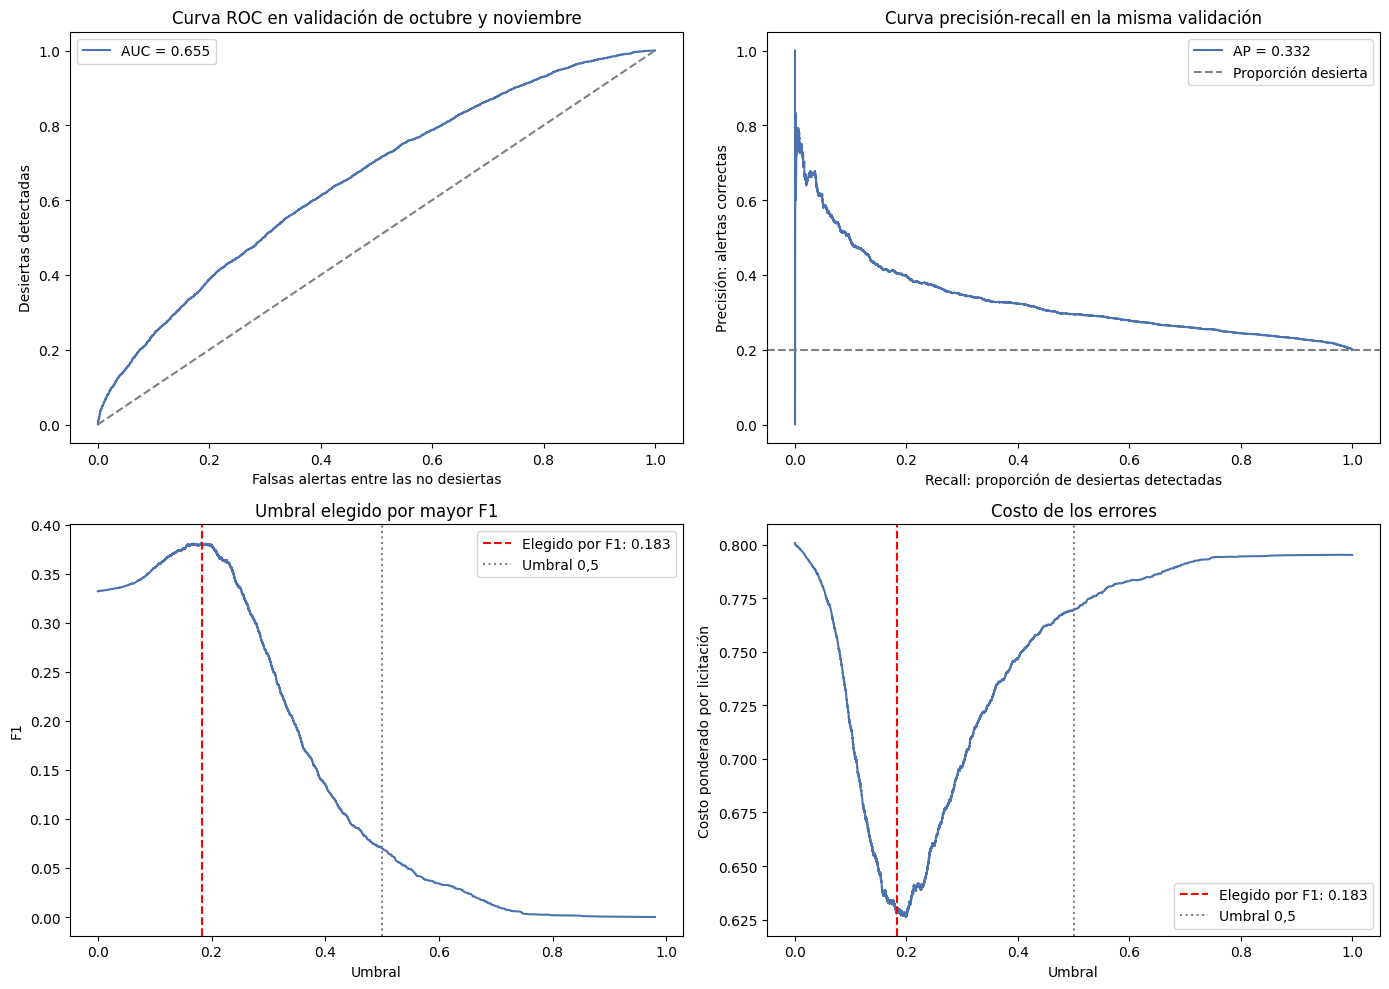

In [104]:
fig, ax = plt.subplots(2, 2, figsize=(14, 10))
fpr, tpr, _ = roc_curve(y_val_umbral, proba_umbral)
ax[0, 0].plot(fpr, tpr, label=f"AUC = {metricas_umbral['roc_auc']:.3f}")
ax[0, 0].plot([0, 1], [0, 1], "--", color="gray")
ax[0, 0].set(xlabel="Falsas alertas entre las no desiertas", ylabel="Desiertas detectadas",
             title="Curva ROC en validación de octubre y noviembre")
ax[0, 0].legend()
precision_curva, recall_curva, _ = precision_recall_curve(y_val_umbral, proba_umbral)
ax[0, 1].plot(recall_curva, precision_curva, label=f"AP = {metricas_umbral['ap']:.3f}")
ax[0, 1].axhline(y_val_umbral.mean(), linestyle="--", color="gray", label="Proporción desierta")
ax[0, 1].set(xlabel="Recall: proporción de desiertas detectadas", ylabel="Precisión: alertas correctas",
             title="Curva precisión-recall en la misma validación")
ax[0, 1].legend()
ax[1, 0].plot(curva_umbral["threshold"], curva_umbral["f1"])
ax[1, 0].set(xlabel="Umbral", ylabel="F1", title="Umbral elegido por mayor F1")
ax[1, 1].plot(curva_costos_umbral["threshold"], curva_costos_umbral["costo_por_licitacion"])
ax[1, 1].set(xlabel="Umbral", ylabel="Costo ponderado por licitación", title="Costo de los errores")
for panel in ax[1]:
    panel.axvline(mejor_threshold, color="red", linestyle="--", label=f"Elegido por F1: {mejor_threshold:.3f}")
    panel.axvline(0.5, color="gray", linestyle=":", label="Umbral 0,5")
    panel.legend()
plt.tight_layout()


# 5. Árboles y ensambles

El **árbol** divide las licitaciones mediante reglas sobre sus datos. Su profundidad y el mínimo de registros por hoja limitan reglas demasiado específicas. **Random Forest** combina muchos árboles y promedia sus resultados; cada árbol usa una muestra de los datos y una parte de las variables.

La siguiente tabla recupera la comparación inicial de ambos modelos en la validación de **agosto y septiembre**, con el mismo umbral **0,5**. Incluye falsas alertas, desiertas no detectadas y costo ponderado, además de F1 y Average Precision. Permite ver si detectar más desiertas también genera más falsas alertas. No se vuelven a entrenar ni se cambian sus parámetros en esta sección. La selección del modelo ya se hizo en la parte 3.


In [105]:
comparacion_arbol_bosque = pd.DataFrame(resultados_base).loc[
    lambda tabla: tabla["modelo"].isin(["arbol_estructural", "bosque_estructural"]),
    ["modelo", "threshold", "ap", "f1", "precision", "recall",
     "falsos_positivos", "falsos_negativos", "costo_por_licitacion"]
].copy()
comparacion_arbol_bosque["modelo"] = comparacion_arbol_bosque["modelo"].replace({
    "arbol_estructural": "Árbol", "bosque_estructural": "Random Forest"
})
display(comparacion_arbol_bosque.rename(columns=ETIQUETAS_RESULTADOS))


,Modelo,Umbral,Average Precision,F1,Precisión,Recall,Falsas alertas,Desiertas no detectadas,Costo por licitación
0,Árbol,0.5,0.268504,0.361408,0.229850,0.845122,14572,797,0.689131
1,Random Forest,0.5,0.296322,0.366386,0.243826,0.736689,11757,1355,0.666321


# 6. Decisión final

El modelo y sus parámetros se eligieron con la validación de agosto y septiembre. El umbral se eligió por F1 con las publicaciones del 1 de octubre al 14 de noviembre. Los pesos de los errores se fijaron con el entrenamiento inicial. Ninguna de esas decisiones se cambia al mirar la evaluación final.

Ahora se entrena con las publicaciones anteriores al 15 de noviembre y se evalúa con las restantes de 2024. Se reportan F1, precisión, recall, Average Precision, la matriz de confusión y los costos ponderados total y por licitación. Una falsa alerta cuenta 1 y una desierta no detectada cuenta aproximadamente 3,99.

Un organismo podría usar las alertas para revisar las bases antes del cierre. La precisión indica qué parte de esas revisiones tendría sentido; el recall muestra qué parte de las licitaciones que terminan desiertas se habría detectado. El costo ponderado ayuda a comparar ambos errores con la regla de pesos elegida, pero no mide dinero ni retrasos reales. Brier describe el error de las probabilidades; menor es mejor y no se usa para reajustar el modelo.


In [106]:
# Se evalúa únicamente el ganador previamente cerrado; D no ajusta ninguna decisión.
modelo_evaluacion = ajustar_pipeline(
    clone(mejor_modelo_config), X_train_umbral, y_train_umbral, "ABC"
)
proba_test_temporal = modelo_evaluacion.predict_proba(X_test_temporal)[:, 1]
metricas_test_temporal = metricas_con_umbral(y_test_temporal, proba_test_temporal, mejor_threshold)
display(pd.Series(metricas_test_temporal).drop("matriz_confusion").rename(index=ETIQUETAS_RESULTADOS))
display(pd.DataFrame(
    metricas_test_temporal["matriz_confusion"],
    index=["real: no desierta", "real: desierta"],
    columns=["predicha: no desierta", "predicha: desierta"]
))

Umbral                                0.182694
F1                                     0.37919
Precisión                             0.268794
Recall                                0.643463
Average Precision                     0.344784
Área bajo ROC                         0.647093
Error de probabilidades (Brier)       0.151927
Proporción real desierta              0.202003
Proporción de alertas                 0.483572
Falsas alertas                            5155
Desiertas no detectadas                   1050
Costo de falsas alertas                 5155.0
Costo de casos no detectados       4191.293724
Costo total                        9346.293724
Costo por licitación                  0.641079
dtype: object

,predicha: no desierta,predicha: desierta
real: no desierta,6479,5155
real: desierta,1050,1895


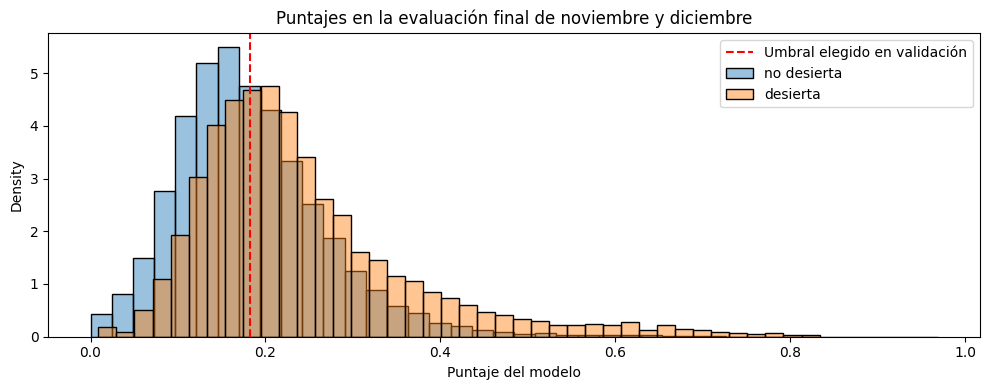

In [107]:
fig, ax = plt.subplots(figsize=(10, 4))
for clase, color, etiqueta in ((0, "tab:blue", "no desierta"), (1, "tab:orange", "desierta")):
    sns.histplot(
        proba_test_temporal[y_test_temporal == clase], bins=40, stat="density",
        color=color, alpha=0.45, label=etiqueta, ax=ax
    )
ax.axvline(mejor_threshold, color="red", linestyle="--", label="Umbral elegido en validación")
ax.set(xlabel="Puntaje del modelo", title="Puntajes en la evaluación final de noviembre y diciembre")
ax.legend()
plt.tight_layout()


## Resumen y revisión de los datos

Se comparan los resultados de cada bloque con su umbral correspondiente. Después se revisa si cambian los datos faltantes, monedas, categorías, regiones, plazos y longitudes del texto. Los datos de Kaggle se usan aquí sin etiquetas, solo para describir sus características. Esta revisión no cambia el modelo, el umbral ni los pesos de los errores.


In [108]:
resumen_predicciones = pd.DataFrame([
    {"particion": "B (selección, umbral 0.5)", "n": len(val_hparam), **mejor_resultado_hparam},
    {"particion": "C (selección de umbral)", "n": len(val_umbral), **metricas_umbral},
    {"particion": "D (evaluación final)", "n": len(test_temporal), **metricas_test_temporal}
]).drop(columns=["modelo", "params"])
display(resumen_predicciones[[
    "particion", "n", "threshold", "ap", "f1", "precision", "recall",
    "falsos_positivos", "falsos_negativos", "costo_por_licitacion"
]].rename(columns=ETIQUETAS_RESULTADOS))

test_features = construir_features(test_df, referencia=datos)
datos_por_bloque = {**bloques, "E": test_df}
features_por_bloque = {
    "A": X_train_modelos, "B": X_val_hparam, "C": X_val_umbral,
    "D": X_test_temporal, "E": test_features
}
print("Porcentaje de nulos por columna de origen")
display(pd.DataFrame({nombre: df[COLUMNAS_ORIGEN].isna().mean() * 100 for nombre, df in datos_por_bloque.items()}))
print("Medianas de plazos y longitudes")
columnas_estabilidad = ["pub_dias_postulacion", "pub_dias_consultas", "titulo_largo", "descripcion_larga"]
display(pd.DataFrame({nombre: X[columnas_estabilidad].median() for nombre, X in features_por_bloque.items()}))
print("Proporciones de categorías, modalidades, regiones y monedas")
display(pd.concat({
    col: pd.DataFrame({nombre: X[col].value_counts(normalize=True) for nombre, X in features_por_bloque.items()})
    for col in ["pub_moneda", "pub_modalidad", "region", "categoria_principal"]
}, names=["variable", "valor"]).fillna(0))
print("Montos por moneda: no se mezclan unidades")
display(pd.concat({
    nombre: df.groupby("pub_moneda", dropna=False)["pub_monto_estimado"].agg(["count", "median"])
    for nombre, df in datos_por_bloque.items()
}, names=["bloque", "moneda"]))

,Bloque,Registros,Umbral,Average Precision,F1,Precisión,Recall,Falsas alertas,Desiertas no detectadas,Costo por licitación
0,"B (selección, umbral 0.5)",25762,0.500000,0.337993,0.077713,0.683871,0.041197,98,4934,0.768306
1,C (selección de umbral),21308,0.182694,0.331766,0.381445,0.272709,0.634393,7182,1552,0.627799
2,D (evaluación final),14579,0.182694,0.344784,0.379190,0.268794,0.643463,5155,1050,0.641079


Porcentaje de nulos por columna de origen


,A,B,C,D,E
pub_fecha,0.000000,0.000000,0.000000,0.000000,0.000000
pub_titulo,0.000000,0.000000,0.042238,0.000000,0.000000
pub_descripcion,0.000000,0.000000,0.042238,0.000000,0.000000
pub_monto_estimado,45.050823,41.813524,41.439835,46.031964,53.135737
pub_moneda,45.067324,41.848459,41.491459,46.038823,53.154061
pub_metodo,0.014301,0.065989,0.075089,0.150902,0.435201
pub_modalidad,0.000000,0.000000,0.000000,0.000000,0.000000
pub_n_items,0.000000,0.000000,0.000000,0.000000,0.000000
pub_cantidad_total,0.000000,0.000000,0.000000,0.000000,0.000000
pub_n_categorias,0.000000,0.000000,0.000000,0.000000,0.000000


Medianas de plazos y longitudes


,A,B,C,D,E
pub_dias_postulacion,9.914,9.965,9.155,9.89,10.257
pub_dias_consultas,3.000,3.000,3.000,3.00,4.000
titulo_largo,48.000,49.000,49.000,49.00,48.000
descripcion_larga,157.000,160.000,159.000,162.00,181.000


Proporciones de categorías, modalidades, regiones y monedas


A  \
variable            valor                                                          
pub_moneda          CLF                                                 0.004224   
                    CLP                                                 0.541945   
                    EUR                                                 0.000011   
                    USD                                                 0.003146   
                    desconocido                                         0.450673   
...                                                                          ...   
categoria_principal Servicios medioambientales                          0.002574   
                    Servicios profesionales, administrativos y cons...  0.088852   
                    Tecnologías de la información, telecomunicacion...  0.048535   
                    Vehículos y equipamiento en general                 0.029130   
                    desconocido                                         0.000209   

                                                                               B  \
variable            valor                                                          
pub_moneda          CLF                                                 0.003610   
                    CLP                                                 0.574412   
                    EUR                                                 0.000000   
                    USD                                                 0.003494   
                    desconocido                                         0.418485   
...                                                                          ...   
categoria_principal Servicios medioambientales                          0.002290   
                    Servicios profesionales, administrativos y cons...  0.112763   
                    Tecnologías de la información, telecomunicacion...  0.052170   
                    Vehículos y equipamiento en general                 0.025037   
                    desconocido                                         0.000078   

                                                                               C  \
variable            valor                                                          
pub_moneda          CLF                                                 0.003895   
                    CLP                                                 0.576966   
                    EUR                                                 0.000047   
                    USD                                                 0.004177   
                    desconocido                                         0.414915   
...                                                                          ...   
categoria_principal Servicios medioambientales                          0.001079   
                    Servicios profesionales, administrativos y cons...  0.099493   
                    Tecnologías de la información, telecomunicacion...  0.058898   
                    Vehículos y equipamiento en general                 0.022714   
                    desconocido                                         0.000141   

                                                                               D  \
variable            valor                                                          
pub_moneda          CLF                                                 0.004321   
                    CLP                                                 0.532204   
                    EUR                                                 0.000000   
                    USD                                                 0.003087   
                    desconocido                                         0.460388   
...                                                                          ...   
categoria_principal Servicios medioambientales                          0.001166   
                    Servicios profesionales,

Montos por moneda: no se mezclan unidades


count        median
bloque moneda                     
A      CLF       384  1.952750e+03
       CLP     49265  6.518000e+06
       EUR         1  2.500000e+07
       USD       286  3.345418e+04
       NaN        15  5.000000e+02
B      CLF        93  2.100000e+03
       CLP     14798  6.500000e+06
       USD        90  3.157700e+04
       NaN         9  3.500000e+03
C      CLF        83  2.614000e+03
       CLP     12294  6.500000e+06
       EUR         1  3.600000e+03
       USD        89  2.320000e+04
       NaN        11  3.500000e+03
D      CLF        63  2.170000e+03
       CLP      7759  8.000000e+06
       USD        45  5.200000e+04
       NaN         1  9.900000e+01
E      CLF       130  2.014060e+03
       CLP     10041  2.427600e+07
       USD        55  5.000000e+04
       NaN         4  5.475000e+03

## Predicción y archivo para Kaggle

Se vuelve a entrenar el modelo elegido con todo 2024 y se conserva el umbral elegido por F1. Los conteos de publicaciones anteriores para 2025 usan solo datos de 2024. Antes de escribir el archivo se comprueban sus columnas, etiquetas, tamaño y orden de identificadores.


In [109]:
X_2024 = construir_features(datos)
y_2024 = datos[TARGET].astype(int)
assert mejor_threshold == decisiones_cerradas["umbral"]
for clave, valor in decisiones_cerradas["parametros"].items():
    assert mejor_modelo_config.get_params()[clave] == valor
modelo_final = ajustar_pipeline(clone(mejor_modelo_config), X_2024, y_2024, "ABCD")
proba_test = modelo_final.predict_proba(test_features)[:, 1]
pred_test = (proba_test >= mejor_threshold).astype(int)

def crear_submission(predicciones, plantilla):
    assert plantilla["id"].equals(test_df["id"])
    resultado = pd.DataFrame({"id": test_df["id"], TARGET: predicciones})
    assert list(resultado.columns) == ["id", TARGET]
    assert len(resultado) == 21829 and resultado["id"].is_unique
    assert resultado["id"].equals(test_df["id"])
    assert resultado[TARGET].notna().all() and resultado[TARGET].isin([0, 1]).all()
    return resultado

submission = crear_submission(pred_test, sample_submission_df)
plantilla_alterada = sample_submission_df.assign(y_desierta=1 - pred_test)
pd.testing.assert_frame_equal(submission, crear_submission(pred_test, plantilla_alterada))
auditoria_ajustes = pd.DataFrame(registro_ajustes)
assert (auditoria_ajustes["hasta"] < auditoria_ajustes["limite"]).all()
# Todas las verificaciones críticas preceden a la escritura del archivo.
submission.to_csv("submission_pregunta2.csv", index=False)
display(auditoria_ajustes.groupby("etapa", sort=False).agg(
    ajustes=("n", "size"), registros=("n", "first"), desde=("desde", "min"), hasta=("hasta", "max")
))
display(pd.Series({
    "proporcion_predicha_2025": pred_test.mean(),
    "probabilidad_media_2025": proba_test.mean(),
    "probabilidad_p10": np.quantile(proba_test, 0.1),
    "probabilidad_mediana": np.median(proba_test),
    "probabilidad_p90": np.quantile(proba_test, 0.9)
}))

,ajustes,registros,desde,hasta
etapa,,,,
A,45,90904,2024-01-04 17:06:15+00:00,2024-07-31 23:27:03+00:00
AB,1,116666,2024-01-04 17:06:15+00:00,2024-09-30 23:25:01+00:00
ABC,1,137974,2024-01-04 17:06:15+00:00,2024-11-14 22:17:01+00:00
ABCD,1,152553,2024-01-04 17:06:15+00:00,2024-12-31 22:29:20+00:00


proporcion_predicha_2025    0.539283
probabilidad_media_2025     0.207979
probabilidad_p10            0.096426
probabilidad_mediana        0.191991
probabilidad_p90            0.333425
dtype: float64

In [110]:
submission.head()

,id,y_desierta
0,47254358932,0
1,295671198916,0
2,214756376398,0
3,404842360472,1
4,899379189128,1


Después de ejecutar todo el notebook, `submission_pregunta2.csv` contiene `id` y `y_desierta`, con el mismo orden de los datos de Kaggle. La proporción de alertas depende del umbral; por sí sola no demuestra que las probabilidades sean correctas o incorrectas.

La pauta indica que los datos de entrada se conocían al publicar. Falta comprobar el proceso de extracción y cuándo estuvieron disponibles los resultados de cada licitación. Por eso, el historial usa solo conteos de publicaciones anteriores y no sus resultados. Una mejora pequeña en una validación no demuestra mayor capacidad de generalización.
